## Port accessibility - terminal congestion (quay)
In this notebook, we set up a basic simulation in which three vessels are bound for the same terminal in a port. The terminal consists of a single quay. At the quay, the vessels berth, unload cargo, and deberth, after they sail back to sea. We examine terminal congestion and consider berth occupation from the terminal's point-of-view.

In [1]:
# package(s) used for creating and geo-locating the graph
import networkx as nx
from pyproj import Geod
from shapely.geometry import Point, LineString

# package(s) related to the hydrodynamics and tidal windows
import xarray as xr

# load OpenTNSim core mixins
from opentnsim.core import Identifiable, Movable, VesselProperties
from opentnsim.core.utils import create_object

# load OpenTNSim environment mixin to add hydrodynamic data to the environment
from opentnsim.environment.mixins.hydrodynamics import HydrodynamicData

# load OpenTNSim graph utils
from opentnsim.graph.calculations import calculate_distance_along_path
from opentnsim.graph.visualizations import plot_graph
from opentnsim.graph.mixins import DiGraph

from opentnsim.model import Simulation

# load OpenTNSim port module mixins and utils
from opentnsim.port.mixins.rules import Rule, TrafficRules
from opentnsim.port.mixins.tidal_accessibility import HasDraughtRestrictions
from opentnsim.port.mixins.anchorage_area import IsAnchorage, CanWaitAtAnchorage
from opentnsim.port.mixins.port import IsPort, HasPortAccess
from opentnsim.port.mixins.berth import IsQuay
from opentnsim.port.mixins.terminal import IsTerminal, TerminalHandable
from opentnsim.port.utils import (
    add_ukc_policy_to_node, 
    add_traffic_encountering_restriction_to_edge, 
    add_traffic_encountering_exception_to_edge,
    add_traffic_overtaking_restriction_to_edge, 
    add_traffic_reservation_to_edge,
    )

# package(s) related to the simulation (creating the vessel, running the simulation)
import datetime
import simpy
import opentnsim

# package(s) needed for inspecting the output
import pandas as pd
import numpy as np

# package(s) for plotting
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

print("This notebook is executed with OpenTNSim version {}".format(opentnsim.__version__))

This notebook is executed with OpenTNSim version 2.3.2a2.dev3+g514a752b4.d20260603


#### Define input
vessel

In [2]:
vessel_length = 200
vessel_beam = 40
vessel_draught = 12
vessel_speed = 4.5 #m/s
vessel_loading_time = 6 #hours

infrastructure

In [3]:
waterway_length = 30000 #meters

harbour_basin_depth = 16.5
anchorage_area_depth = 17

#### 0. Create environment

In [4]:
# set simulation time
simulation = Simulation(
    simulation_start = datetime.datetime(2026, 1, 1, 0, 0, 0),
    simulation_stop = datetime.datetime(2026, 1, 8, 0, 0, 0),
)
env = simulation.env

#### 1. Create graph
Next we create a network (a graph) along which the vessel can move. For this case we create a single edge of 100 km exactly.

In [5]:
# initialize geodetic calculator with WGS84 ellipsoid
geod = Geod(ellps="WGS84")

In [6]:
# starting point (longitude, latitude)
coordinates_sea = (0,0)

# compute the other point 100 km East from Point 0
coordinates_port = geod.fwd(coordinates_sea[0], coordinates_sea[1], 90 ,waterway_length)[:2] # East from Point 0

# define nodes with their geographic coordinates
coordinates_waterway = {"Sea": coordinates_sea,
                        "Port basin": coordinates_port,}

In [7]:
# create list of edges
edges = [("Sea", "Port basin"), ("Port basin", "Sea")] # bi-directional edge

In [8]:
# create a directed graph
graph = DiGraph()

# add nodes
for name, coordinates in coordinates_waterway.items():
    graph.add_node(name = name, geometry=Point(coordinates))

# add edges
for edge in edges:
    graph.add_edge(edge)

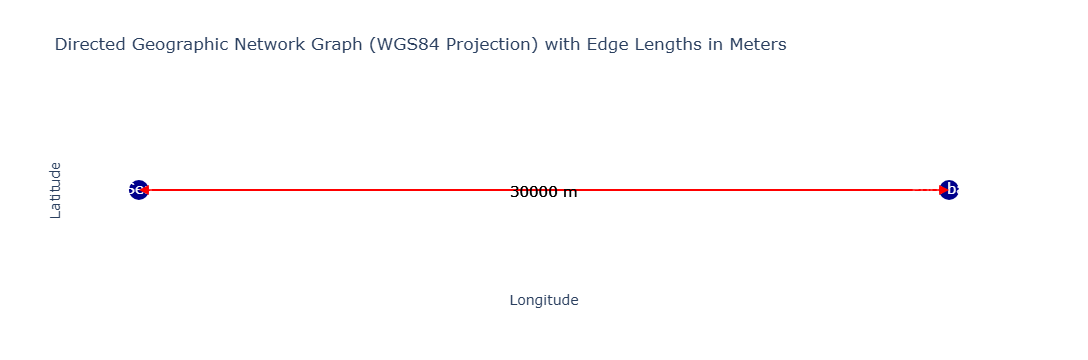

In [9]:
graph.plot()

In [10]:
# add graph to environment
simulation.add_graph(graph)

#### 1+ Adding infrastructure

In [11]:
port = IsPort(env=env, name = "Port", port_entry_nodes=['Sea'])

In [12]:
anchorage = IsAnchorage(env=env, capacity=20, name = 'Anchorage', node = 'Sea', depth = anchorage_area_depth, geometry=env.graph.nodes['Sea']['geometry'], port = port)

In [13]:
quay = IsQuay(env=env, length=500, depth=harbour_basin_depth, name='Quay',node='Port basin')
berths = [quay]

terminal = IsTerminal(env=env, name = 'Terminal', berths=berths, port = port)

#### 2. Create agents

In [14]:
# make your preferred Vessel class out of available mix-ins.
Vessel = create_object(
    "Vessel", 
    (HasPortAccess,
     TerminalHandable,
     CanWaitAtAnchorage,
     HasDraughtRestrictions,
     Identifiable, # allows to give the object a name and a random ID,
     Movable,      # allows the object to move, with a fixed speed, while logging this activity
     VesselProperties,
    ), 
)

In [15]:
def mission(env, vessel):
    """
    Method that defines the mission of the vessel. 
    
    In this case: 
        keep moving along the path until its end point is reached
    """
    yield from vessel.move()

In [16]:
def create_vessel(
    name, 
    route, 
    next_destination,      
    vessel_speed = 4.5,
    berthing_time = 15, 
    loading_time = 6,
    deberthing_time = 5, 
    vessel_length = vessel_length,
    vessel_beam = vessel_beam,
    vessel_draught = vessel_draught,
    arrival_time = env.simulation_start
):
    data_vessel = {"env": env,                                        # needed for simpy simulation
                   "name": name,                                      # required by Identifiable
                   "geometry": env.graph.nodes[route[0]]['geometry'], # required by Locatable
                   "route": route,                                    # required by Routeable
                   "v": vessel_speed,                                 # required by Movable, 1 m/s to check if the distance is covered in the expected time
                   "bound": 'inbound',
                   "terminal": terminal,
                   "berthing_time":berthing_time, #minutes
                   "loading_time": loading_time, #hours
                   "deberthing_time":deberthing_time, #minutes
                   "next_destination":next_destination,
                   "type":"tanker",
                   "L":vessel_length,
                   "B":vessel_beam,
                   "T":vessel_draught,
                   "arrival_time":arrival_time,
                   }
    vessel = Vessel(**data_vessel)
    return vessel

In [17]:
# create vessel from a dict 
route = nx.dijkstra_path(env.graph, "Sea", "Port basin")
vessel_1 = create_vessel("vessel_1", route, "Sea")
vessel_2 = create_vessel("vessel_2", route, "Sea", arrival_time = env.simulation_start + pd.Timedelta(hours=2))
vessel_3 = create_vessel("vessel_3", route, "Sea", arrival_time = env.simulation_start + pd.Timedelta(hours=4))

# start the simulation
simulation.add_vessel(vessel_1, mission)
simulation.add_vessel(vessel_2, mission)
simulation.add_vessel(vessel_3, mission)

#### 3. Run simulation

In [18]:
simulation.run()

0 days 06:05:00 2026-01-01 02:06:06.666667 0 days 06:00:00
0 days 06:05:00 2026-01-01 04:06:06.666667 0 days 06:00:00
0 days 06:05:00 2026-01-01 08:26:07 0 days 06:00:00


#### 4. Inspect output

##### Logbook
We can now inspect  the simulation output by inspecting the _vessel.logbook_. Note that the _Log_ mix-in was included when we added _Movable_. The _vessel.logbook_ keeps track of the moving activities of the vessel. For each discrete event OpenTNSim logs an event message, the start/stop time and the location. The _vessel.logbook_ is of type dict. For convenient inspection it can be loaded into a Pandas dataframe. 

In [19]:
# load the logbook data into a dataframe
for vessel in env.vessels['obj']:
    df = pd.DataFrame.from_dict(vessel.logbook)
    
    print("'{}' logbook data:".format(vessel.name))  
    print('')
    
    display(df)
    
    if not df.empty:
        trip_distance = calculate_distance_along_path(graph, vessel.route)
        trip_duration = datetime.timedelta.total_seconds(vessel.logbook[-1]['Timestamp'] - vessel.logbook[0]['Timestamp'])
        print("'{}' travelled a distance of {:.1f} meters".format(vessel.name, trip_distance))
        print("'{}' took {:.1f} seconds to arrive at its destination".format(vessel.name, trip_duration)) 
        print("'{}' travelled at an average speed of {:.1f} meters per second".format(vessel.name, trip_distance/trip_duration))
    else:
        print("The port was not accessible for vessel")
    print('')
    print('')

'vessel_1' logbook data:



,Message,Timestamp,Value,Geometry
0,Sailing from node Sea to node Port basin start,2026-01-01 00:00:00.000000,0.0,POINT (0 0)
1,Sailing from node Sea to node Port basin stop,2026-01-01 01:51:06.666667,30000.0,POINT (0.2694945852358564 0)
2,Berthing start,2026-01-01 01:51:06.666667,30000.0,POINT (0.2694945852358564 0)
3,Berthing stop,2026-01-01 02:06:06.666667,30000.0,POINT (0.2694945852358564 0)
4,Loading start,2026-01-01 02:06:06.666667,30000.0,POINT (0.2694945852358564 0)
5,Loading stop,2026-01-01 08:06:06.666667,30000.0,POINT (0.2694945852358564 0)
6,Deberthing start,2026-01-01 08:06:06.666667,30000.0,POINT (0.2694945852358564 0)
7,Deberthing stop,2026-01-01 08:11:06.666667,30000.0,POINT (0.2694945852358564 0)
8,Sailing from node Port basin to node Sea start,2026-01-01 08:11:06.666667,30000.0,POINT (0.2694945852358564 0)
9,Sailing from node Port basin to node Sea stop,2026-01-01 10:02:13.333333,60000.0,POINT (0 0)


'vessel_1' travelled a distance of 30000.0 meters
'vessel_1' took 36133.3 seconds to arrive at its destination
'vessel_1' travelled at an average speed of 0.8 meters per second


'vessel_2' logbook data:



,Message,Timestamp,Value,Geometry
0,Sailing from node Sea to node Port basin start,2026-01-01 02:00:00.000000,0.0,POINT (0 0)
1,Sailing from node Sea to node Port basin stop,2026-01-01 03:51:06.666667,30000.0,POINT (0.2694945852358564 0)
2,Berthing start,2026-01-01 03:51:06.666667,30000.0,POINT (0.2694945852358564 0)
3,Berthing stop,2026-01-01 04:06:06.666667,30000.0,POINT (0.2694945852358564 0)
4,Loading start,2026-01-01 04:06:06.666667,30000.0,POINT (0.2694945852358564 0)
5,Loading stop,2026-01-01 10:06:06.666667,30000.0,POINT (0.2694945852358564 0)
6,Deberthing start,2026-01-01 10:06:06.666667,30000.0,POINT (0.2694945852358564 0)
7,Deberthing stop,2026-01-01 10:11:06.666667,30000.0,POINT (0.2694945852358564 0)
8,Sailing from node Port basin to node Sea start,2026-01-01 10:11:06.666667,30000.0,POINT (0.2694945852358564 0)
9,Sailing from node Port basin to node Sea stop,2026-01-01 12:02:13.333333,60000.0,POINT (0 0)


'vessel_2' travelled a distance of 30000.0 meters
'vessel_2' took 36133.3 seconds to arrive at its destination
'vessel_2' travelled at an average speed of 0.8 meters per second


'vessel_3' logbook data:



,Message,Timestamp,Value,Geometry
0,Waiting for Terminal start,2026-01-01 04:00:00.000000,0.0,POINT (0 0)
1,Waiting for Terminal stop,2026-01-01 04:06:06.666667,0.0,POINT (0 0)
2,Waiting for Terminal start,2026-01-01 04:06:06.666667,0.0,POINT (0 0)
3,Waiting for Terminal stop,2026-01-01 06:20:00.333333,0.0,POINT (0 0)
4,Sailing from node Sea to node Port basin start,2026-01-01 06:20:00.333333,0.0,POINT (0 0)
5,Sailing from node Sea to node Port basin stop,2026-01-01 08:11:07.000000,30000.0,POINT (0.2694945852358564 0)
6,Berthing start,2026-01-01 08:11:07.000000,30000.0,POINT (0.2694945852358564 0)
7,Berthing stop,2026-01-01 08:26:07.000000,30000.0,POINT (0.2694945852358564 0)
8,Loading start,2026-01-01 08:26:07.000000,30000.0,POINT (0.2694945852358564 0)
9,Loading stop,2026-01-01 14:26:07.000000,30000.0,POINT (0.2694945852358564 0)


'vessel_3' travelled a distance of 30000.0 meters
'vessel_3' took 44533.7 seconds to arrive at its destination
'vessel_3' travelled at an average speed of 0.7 meters per second




##### Berth output
We can plot the occupancy of berths over time. We see that the third vessel has to wait as there is insufficient quay length left when the two prior vessels have already berthed.

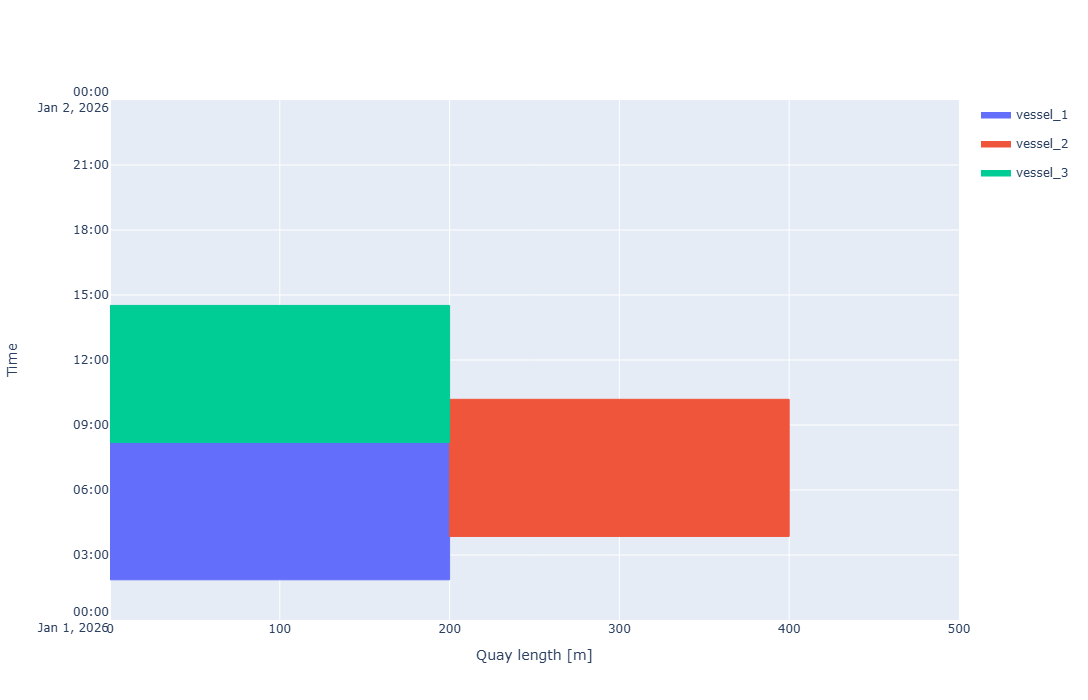

In [20]:
fig = quay.plot_berth_occupation(time_stop = pd.Timestamp('2026-01-02'), style='plotly')
fig

Quay performance

In [21]:
berth_performance = quay.get_berth_performance(time_stop = pd.Timestamp('2026-01-03'))
berth_performance

Total vessels handled                                   3
Average vessel length                               200.0
Shortest service time                     0 days 06:19:45
Vessel_id shortest service time                         0
Average service time                      0 days 06:19:45
Longest service time                      0 days 06:19:45
Vessel_id longest service time                          0
Total service time                        0 days 18:59:15
Berth occupancy (%)                             15.822917
Average waiting time               0 days 00:46:40.111111
Total waiting time                 0 days 02:20:00.333333
Waiting time rate                                0.122893
Causes waiting time                   {'Terminal': 100.0}
dtype: object

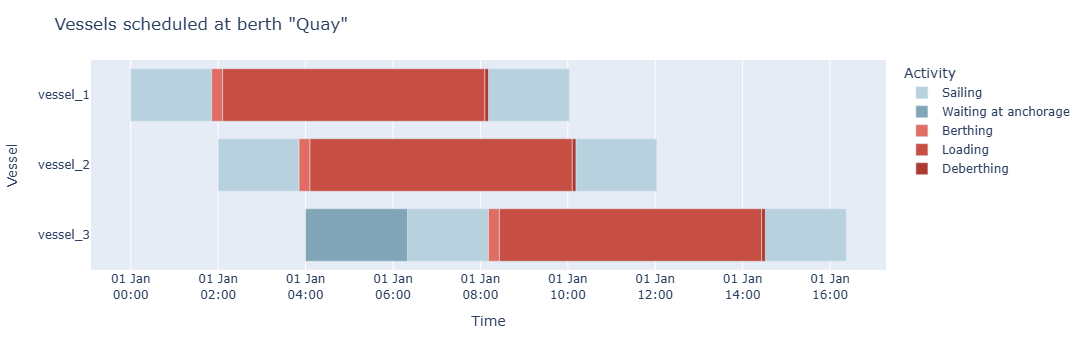

In [22]:
fig = quay.plot_vessel_arrival_timeline()
fig